# ResNet50 v2/v3 — inference

This notebook does not modify checkpoint files. Run the first cell, select a non-empty file using `CHECKPOINT_NAME`, then rerun all cells in order. Legacy v2 checkpoints are supported.


In [1]:
from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from tqdm.auto import tqdm

LOCAL = True
CHECKPOINT_NAME = "v2_S1_2026-10-14_14-14-44-655065.pth"  # Scegliere un file non vuoto.
MODE = "inference"  # "inference" or "saved"
USE_SUBSAMPLE = False
DATA_ROOT_OVERRIDE = None  # Root containing test/; optional
BATCH_SIZE = 32
EXPORT_TENSORBOARD = True

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if LOCAL:
    STORAGE_ROOT = PROJECT_ROOT / "output"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    STORAGE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/AARHUS INTERNSHIP")
MODELS_DIR = STORAGE_ROOT / "models"
RESULTS_ROOT = PROJECT_ROOT / "runs" / "inference_results"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Available checkpoints:")
for path in sorted(MODELS_DIR.glob("*.pth")):
    print(path.name, "|", path.stat().st_size, "byte", "EMPTY FILE" if path.stat().st_size == 0 else "")

Device: cuda
Available checkpoints:
backup_v2_S1_2026-10-14_14-14-44-655065.pth | 94422073 byte 
backup_v2_S2_20epochs_2026-10-14_16-48.pth | 94421881 byte 
backup_v2_S3_2026-10-08_16-09-10-958875.pth | 94425882 byte 
backup_v3_2026-10-12_18-19-20-664416.pth | 94421049 byte 
v2_S1_2026-10-14_13-35-33-166399.pth | 94421497 byte 
v2_S1_2026-10-14_14-14-44-655065.pth | 94422073 byte 
v2_S2_15epochs_2026-10-14_16-15.pth | 94421497 byte 
v2_S2_2026-10-14_15-44-21-142586.pth | 94421113 byte 
v2_S2_20epochs_2026-10-14_16-48.pth | 94421881 byte 
v2_S3_2026-10-08_16-09-10-958875.pth | 94425882 byte 
v3_2026-10-12_17-47-26-467564.pth | 94420793 byte 
v3_2026-10-12_18-19-20-664416.pth | 94421049 byte 


## 1. Load and inspect the checkpoint

Set `CHECKPOINT_NAME` in the previous cell. The version, scale, class labels, and normalization statistics are read from the checkpoint. Statistics are not recomputed on the test set.
Older files containing only model weights lack the required metadata and are rejected.


In [2]:
if MODE not in {"inference", "saved"}:
    raise ValueError("MODE must be 'inference' or 'saved'")
if not CHECKPOINT_NAME:
    raise ValueError("CHECKPOINT_NAME must be set to one of the listed checkpoint files.")
CHECKPOINT_PATH = Path(CHECKPOINT_NAME)
if not CHECKPOINT_PATH.is_absolute():
    CHECKPOINT_PATH = MODELS_DIR / CHECKPOINT_PATH

checkpoint = torch.load(CHECKPOINT_PATH, 
                        map_location="cpu", 
                        weights_only=True)
required = { "representation", "scale", 
            "normalization", "idx_to_class",
            "model_state_dict", "completed_epochs", 
            "num_classes"}
if not isinstance(checkpoint, dict) or required - checkpoint.keys():
    raise ValueError("Checkpoint incompleto/legacy: richiesto il formato del notebook v2v3.")
representation_versions = {"cumulative-rank-u16-v1": "v2", 
                           "cumulative-rank-u16-v2": "v2", 
                           "cumulative-rank-u16-v3": "v3"}
inferred_version = representation_versions.get(checkpoint["representation"])
VERSION, SCALE = checkpoint.get("version", inferred_version), checkpoint["scale"]

print("Checkpoint:", CHECKPOINT_PATH.resolve(), "| version:", VERSION, "| S:", SCALE)
print("Training manifest:", checkpoint.get("train_manifest"))
print("Test manifest:", checkpoint.get("test_manifest"))

REPRESENTATION = checkpoint["representation"]
if VERSION not in {"v2", "v3"}:
    raise ValueError("Version/rappresentation not supported")
if VERSION == "v3" and SCALE is not None:
    raise ValueError("Checkpoint v3 should have scale=None")
NUM_CLASSES = checkpoint["num_classes"]
idx_to_class = {int(k): v for k, v in checkpoint["idx_to_class"].items()}
CLASS_NAMES = [idx_to_class[i] for i in range(NUM_CLASSES)]
MEAN = float(checkpoint["normalization"]["mean"])
STD = float(checkpoint["normalization"]["std"])
EPOCH = checkpoint["completed_epochs"]
history = checkpoint.get("history", [])
EXPERIMENT = f"v2_S{SCALE}" if VERSION == "v2" else "v3_adaptive"
print(f"{EXPERIMENT}; epochs={EPOCH}; mean={MEAN:.6f}; std={STD:.6f}")

Checkpoint: C:\Users\Edward\Desktop\AARHUS\output\models\v2_S1_2026-10-14_14-14-44-655065.pth | version: v2 | S: 1
Training manifest: C:\Users\Edward\Desktop\AARHUS\output\v2_cumulative_rank-s1\train\manifest_train.json
Test manifest: C:\Users\Edward\Desktop\AARHUS\output\v2_cumulative_rank-s1\test\manifest_test.json
v2_S1; epochs=20; mean=1016.421691; std=1995.619396


## 2. Test set and model (inference mode only)

Locally, the notebook reads NPZ files from `output/<dataset>/test/`. In Colab, it reads these files or `test.zip` directly from Drive, without requiring the training set or extracting the archive.
Reading from Drive may be slow. Use `DATA_ROOT_OVERRIDE` to point to a local copy.
The loader checks the representation, scale, dtype, and shape. Inputs are converted to float32 and normalized as `(z - mean_train) / std_train`, without augmentation or division by 65535.


In [3]:
class TestMaps(Dataset):
    def __init__(self, root):
        candidates = [root / "test" / name for name in("manifest_test.json", 
                                                       "manifest.json", 
                                                       "subsample_manifest_test.json")]
        found = [p for p in candidates if p.is_file()]
        if not found and (root / "manifest_test.json").is_file():
            found = [root / "manifest_test.json"]
        if len(found) != 1:
            raise ValueError(f"Expected unique test manifest in {root}: {found}")
        self.manifest_path = found[0]
        
        raw = self.manifest_path.read_bytes()
        self.manifest_sha256 = hashlib.sha256(raw).hexdigest()
        manifest = json.loads(raw)

        self.samples = manifest["samples"]
        names = [s["file"] for s in self.samples]

        self.folder = self.manifest_path.parent
        if not all((self.folder / n).is_file() for n in names):
            self.folder = root / "test"
        self.archive_path = None
        if not all((self.folder / n).is_file() for n in names):
            self.archive_path = root / "test.zip"
            with ZipFile(self.archive_path) as archive:
                members = [n for n in archive.namelist() if n.endswith(".npz")]
            self.members = {n.replace("\\", "/").rsplit("/", 1)[-1]: n for n in members}

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        from io import BytesIO
        sample = self.samples[index]
        source = self.folder / sample["file"]
        if self.archive_path is not None:
            with ZipFile(self.archive_path) as archive:
                source = BytesIO(archive.read(self.members[sample["file"]]))
        with ZipFile(source) as archive:
            representation = json.loads(archive.read("metadata.json"))["representation"]
        if representation_versions.get(representation.get("name")) != VERSION:
            raise ValueError(f"Rappresentazione errata: {sample['file']}")
        scale = representation.get("scale")
        if (VERSION == "v2" and scale != SCALE) or (VERSION == "v3" and
                (type(scale) is not int or not 0 <= scale <= 65535)):
            raise ValueError(f"Scala errata: {sample['file']}")
        if hasattr(source, "seek"):
            source.seek(0)
        with np.load(source, allow_pickle=False) as archive:
            z = archive["z_u16"]
        if z.dtype != np.uint16 or z.shape != (224, 224):
            raise ValueError("Atteso z_u16 uint16 [224,224]")
        x = torch.from_numpy(z.astype(np.float32)).unsqueeze(0)
        return (x - MEAN) / STD, sample["label"]

if MODE == "inference":
    dataset_name = f"v2_cumulative_rank-s{SCALE}" if VERSION == "v2" else "v3_cumulative_rank_adaptive"
    data_root = Path(DATA_ROOT_OVERRIDE) if DATA_ROOT_OVERRIDE else STORAGE_ROOT / dataset_name
    if USE_SUBSAMPLE:
        data_root = data_root / "subsample"
    test_data = TestMaps(data_root)
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    # Identica architettura/state_dict al CustomResNet50 del training; nessun download.
    model = models.resnet50(weights=None, num_classes=NUM_CLASSES)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(DEVICE).eval()
    print("Campioni test:", len(test_data))

Campioni test: 10000


## 3. Evaluate the model or retrieve saved results

Loss is the mean cross-entropy per sample. In `inference` mode, probabilities and predictions are also retained for later analysis without repeating the forward pass.
In `saved` mode, individual probabilities cannot be recovered from the saved aggregate metrics.


In [4]:
probabilities = targets = predictions = None
if MODE == "inference":
    loss_sum, count = 0.0, 0
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    probability_batches, target_batches = [], []
    with torch.inference_mode():
        for x, y in tqdm(test_loader, desc="Test"):
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            if not torch.isfinite(logits).all():
                raise ValueError("Logit non finiti")
            loss_sum += nn.functional.cross_entropy(logits, y, reduction="sum").item()
            count += y.numel()
            pred = logits.argmax(dim=1)
            pairs = (y * NUM_CLASSES + pred).cpu().numpy()
            confusion += np.bincount(pairs, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
            probability_batches.append(logits.softmax(dim=1).cpu().numpy())
            target_batches.append(y.cpu().numpy())
    test_loss = loss_sum / count
    probabilities = np.concatenate(probability_batches)
    targets = np.concatenate(target_batches)
    predictions = probabilities.argmax(axis=1)
    test_source = {"manifest": str(test_data.manifest_path),
                   "manifest_sha256": test_data.manifest_sha256}
else:
    saved = checkpoint.get("test_metrics")
    if not saved or saved.get("epoch") != EPOCH:
        raise ValueError("Metriche test assenti o relative ad altre epoche: usare inference")
    confusion = np.asarray(saved["confusion_counts"])
    if (confusion.shape != (NUM_CLASSES, NUM_CLASSES) or
        not np.issubdtype(confusion.dtype, np.integer) or (confusion < 0).any() or confusion.sum() == 0):
        raise ValueError("Confusion matrix salvata non valida")
    test_loss = float(saved["loss"])
    test_source = {"manifest": checkpoint.get("test_manifest"), "manifest_sha256": None}
if not np.isfinite(test_loss):
    raise ValueError("Loss non finita")

Test:   0%|          | 0/313 [00:00<?, ?it/s]

## 4. Metrics and confusion matrices

Rows represent true classes; columns represent predicted classes. The diagonal of the row-normalized matrix gives recall per class.
Precision, recall, and F1 are set to 0 when their denominators are zero. Rows with no samples are marked N/A in the normalized plot. Macro averages include all 10 classes.


,num_samples,accuracy_pct,macro_precision,macro_recall,macro_f1,weighted_f1,test_loss,epoch,version,scale
0,10000,46.92,0.48631,0.4692,0.46806,0.46806,1.501466,20,v2,1


,class,precision,recall,f1,support
0,airplane,0.571788,0.454,0.506132,1000
1,automobile,0.336957,0.713,0.457638,1000
2,bird,0.412679,0.345,0.375817,1000
3,cat,0.403394,0.309,0.349943,1000
4,deer,0.475687,0.450,0.462487,1000
5,dog,0.462704,0.397,0.427341,1000
6,frog,0.533875,0.591,0.560987,1000
7,horse,0.527607,0.430,0.473829,1000
8,ship,0.536364,0.472,0.502128,1000
9,truck,0.602041,0.531,0.564293,1000


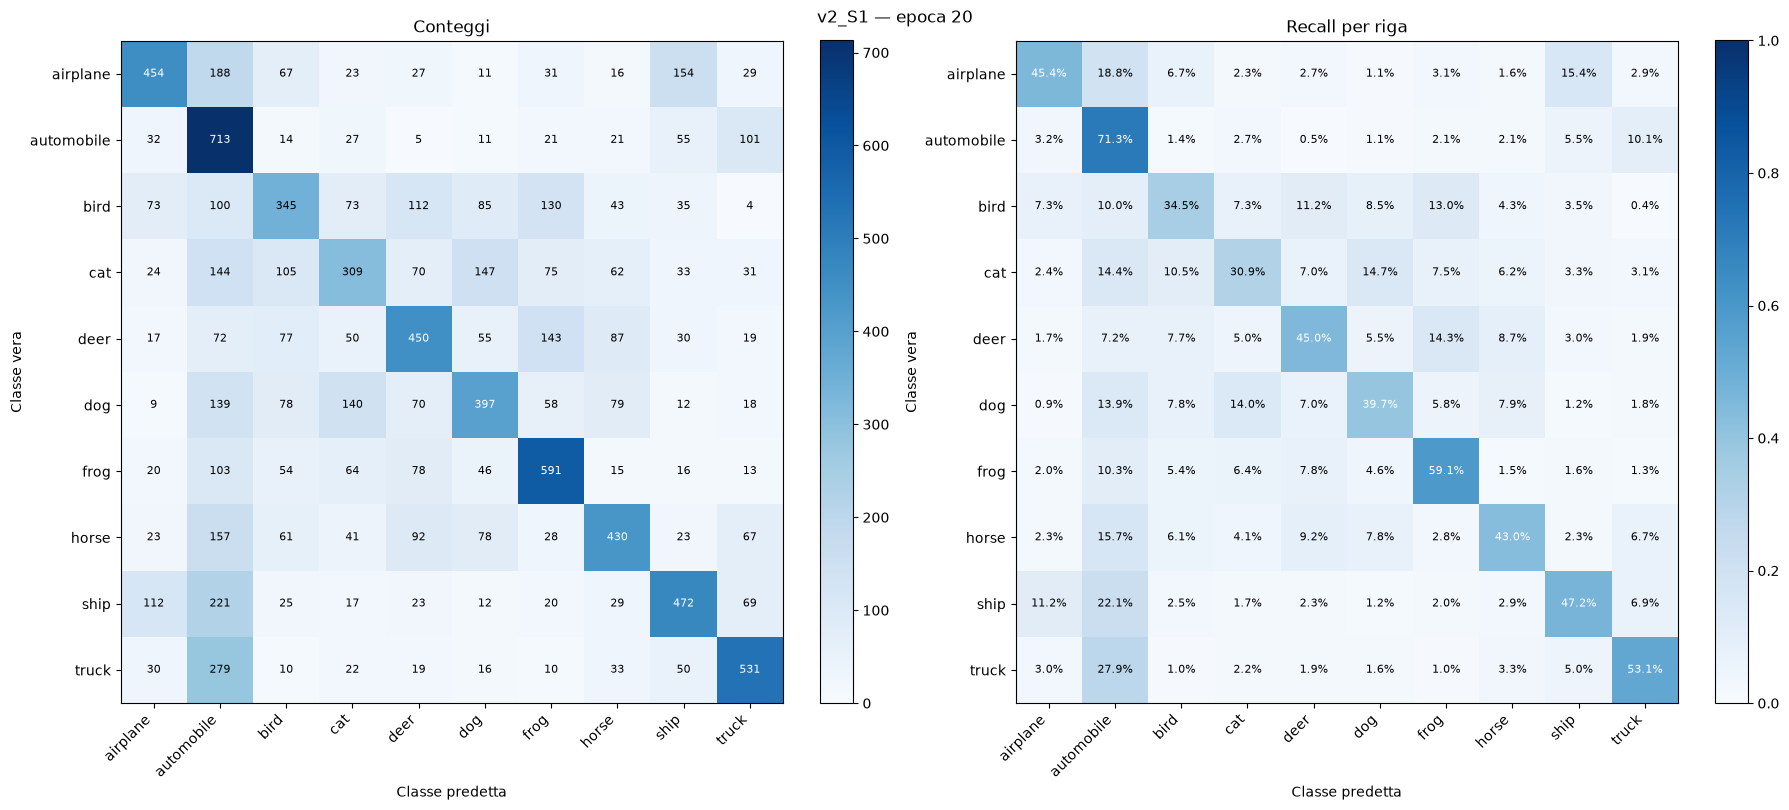

In [5]:
def metrics_from_confusion(cm):
    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    tp = np.diag(cm).astype(float)
    def divide(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)
    precision = divide(tp, predicted)
    recall = divide(tp, support)
    f1 = divide(2 * precision * recall, precision + recall)
    normalized = divide(cm.astype(float), support[:, None])
    per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": precision,
                              "recall": recall, "f1": f1, "support": support})
    summary = {"num_samples": int(cm.sum()), "accuracy_pct": float(100 * tp.sum() / cm.sum()),
               "macro_precision": float(precision.mean()), "macro_recall": float(recall.mean()),
               "macro_f1": float(f1.mean()), "weighted_f1": float(np.dot(f1, support) / cm.sum())}
    return summary, per_class, normalized

summary, per_class, normalized = metrics_from_confusion(confusion)
summary.update({"test_loss": test_loss, "epoch": EPOCH, "version": VERSION, "scale": SCALE})
display(pd.DataFrame([summary]))
display(per_class)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, values, title in zip(axes, [confusion, normalized], ["Conteggi", "Recall per riga"]):
    is_normalized = title != "Conteggi"
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=1 if is_normalized else None)
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
           xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
           xlabel="Classe predetta", ylabel="Classe vera", title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            label = (f"{values[i,j]:.1%}" if confusion[i].sum() else "N/A") if is_normalized else str(values[i,j])
            ax.text(j, i, label, ha="center", va="center", fontsize=8,
                    color="white" if values[i,j] > (values.max() / 2) else "black")
fig.suptitle(f"{EXPERIMENT} — epoca {EPOCH}")
fig.tight_layout()
plt.show()

## 5. Save results

Each execution creates a separate output folder; no checkpoint is overwritten.
`metrics.json` contains provenance information, results, and confusion matrices. CSV files support comparisons across runs.
Per-sample probabilities are available only in `inference` mode.


In [7]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_NAME = f"{CHECKPOINT_PATH.stem}_{MODE}_{stamp}"
RUN_DIR = RESULTS_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
with CHECKPOINT_PATH.open("rb") as stream:
    digest = hashlib.sha256()
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        digest.update(chunk)
report = {"schema": "resnet-v2v3-inference-v1", "checkpoint": str(CHECKPOINT_PATH),
          "checkpoint_sha256": digest.hexdigest(), "mode": MODE, "created_utc": stamp,
          "test_source": test_source, "normalization": checkpoint["normalization"],
          "classes": CLASS_NAMES, "summary": summary, "zero_division": 0,
          "confusion_counts": confusion.tolist(), "confusion_proportions": normalized.tolist(),
          "per_class": per_class.to_dict(orient="records"),
          "device": str(DEVICE), "batch_size": BATCH_SIZE,
          "torch_version": str(torch.__version__)}
(RUN_DIR / "metrics.json").write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")
pd.DataFrame([{**summary, "checkpoint": CHECKPOINT_PATH.name, "mode": MODE}]).to_csv(RUN_DIR / "summary.csv", index=False)
per_class.to_csv(RUN_DIR / "per_class.csv", index=False)
for name, values in [("confusion_counts", confusion), ("confusion_proportions", normalized)]:
    pd.DataFrame(values, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / f"{name}.csv", index_label="true_class")
pd.DataFrame(history).to_csv(RUN_DIR / "training_history.csv", index=False)
fig.savefig(RUN_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
if probabilities is not None:
    np.savez_compressed(RUN_DIR / "predictions.npz", targets=targets, predictions=predictions,
                        probabilities=probabilities, files=np.asarray([s["file"] for s in test_data.samples]),
                        class_names=np.asarray(CLASS_NAMES))
print("Risultati salvati in:", RUN_DIR)

Risultati salvati in: C:\Users\Edward\Desktop\AARHUS\runs\inference_results\v2_S1_2026-10-14_14-14-44-655065_inference_20261015T095227862013Z


## 6. Optional TensorBoard export

Set `EXPORT_TENSORBOARD=True` to export the training history and final test results. If the package is missing, install it in your environment with `%pip install tensorboard`.
The imported history preserves epoch numbers, **not the original event timestamps**. The current export logs training loss, accuracy, and learning rate; it does not export epoch durations.
Figures and scalars use shared tags to compare different checkpoints.


In [8]:
if EXPORT_TENSORBOARD:
    from torch.utils.tensorboard import SummaryWriter
    LOG_ROOT = RESULTS_ROOT / "tensorboard"
    with SummaryWriter(log_dir=str(LOG_ROOT / RUN_NAME)) as writer:
        for entry in history:
            for key, tag in [("loss", "Loss/train"), ("accuracy", "Accuracy_pct/train"), ("lr", "Learning_rate")]:
                if key in entry:
                    writer.add_scalar(tag, entry[key], entry["epoch"])
        writer.add_scalar("Loss/test", test_loss, EPOCH)
        writer.add_scalar("Accuracy_pct/test", summary["accuracy_pct"], EPOCH)
        writer.add_scalar("F1_macro/test", summary["macro_f1"], EPOCH)
        for row in per_class.to_dict(orient="records"):
            for metric in ["precision", "recall", "f1"]:
                writer.add_scalar(f"Per_class/{row['class']}/{metric}", row[metric], EPOCH)
        writer.add_figure("Confusion_matrix/test", fig, EPOCH, close=False)
        writer.add_text("Configuration", json.dumps({"checkpoint": CHECKPOINT_PATH.name,
                        "version": VERSION, "scale": SCALE, "mode": MODE}, indent=2))
    print("Log TensorBoard:", LOG_ROOT)
else:
    print("Esportazione TensorBoard disattivata; JSON/CSV e figure sono già salvati.")

Log TensorBoard: C:\Users\Edward\Desktop\AARHUS\runs\inference_results\tensorboard


To open TensorBoard in the notebook, run the following in a new cell:

```python
%load_ext tensorboard
%tensorboard --logdir "{RESULTS_ROOT / 'tensorboard'}"
```

Alternatively, run `tensorboard --logdir <path/to/inference_results/tensorboard>` in a terminal.
Repeat the notebook with other checkpoints to compare runs.
The `saved` and `inference` runs for the same checkpoint are alternative evaluations, not independent training runs. Compare results obtained on the same test samples.


In [9]:
%load_ext tensorboard
%tensorboard --logdir "{RESULTS_ROOT / 'tensorboard'}"

Reusing TensorBoard on port 6006 (pid 18996), started 1 day, 21:15:33 ago. (Use '!kill 18996' to kill it.)